In [1]:
from gpumap import GPUMAP, GPUMAPParams
from gpumap.data_loader import PreloadMNISTDataLoader

from gpumap.scheduler import DefaultScheduler


from gpumap.estimator import DefaultLinearEstimator


import numpy as np

In [2]:
data_loader = PreloadMNISTDataLoader()

In [3]:
config = GPUMAPParams()
config.n_neighbors = 15
config.n_components = 2
config.n_epochs = 200
config.min_dist = 0.1
config.verbose = True
config.n_instances = data_loader.n_instances
config.n_features = data_loader.n_features

gpumap = GPUMAP(
    data_loader=data_loader,
    params=config,
    scheduler=DefaultScheduler(),
    insertion_estimator=DefaultLinearEstimator(),
    update_estimator=DefaultLinearEstimator(),
    embedding_estimator=DefaultLinearEstimator(),
)

In [4]:
print(f"Running GPUMAP...")
for i in range(7):
    print(f"  Iteration {i+1}...")
    result = gpumap.run_with_n_ops(10000, 5000, 10000)

for i in range(10):
    result = gpumap.run_with_n_ops(0, 10000, 10000)

Running GPUMAP...
  Iteration 1...
  Iteration 2...


[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=10000
[GPUMAP] starting insert(10000), queue size=10000
[GPUMAP] insert done
[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=20000
[GPUMAP] starting insert(10000), queue size=10000
[GPUMAP] insert done
[GPUMAP] update done


  Iteration 3...
  Iteration 4...


[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=30000
[GPUMAP] starting insert(10000), queue size=10000
[GPUMAP] insert done
[GPUMAP] update done


  Iteration 5...


[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=40000
[GPUMAP] starting insert(10000), queue size=10000
[GPUMAP] insert done
[GPUMAP] update done
[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=50000
[GPUMAP] starting insert(10000), queue size=10000


  Iteration 6...


[GPUMAP] insert done
[GPUMAP] update done


  Iteration 7...


[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=60000
[GPUMAP] starting insert(10000), queue size=10000
[GPUMAP] insert done
[GPUMAP] update done
[GPUMAP] run() start: insert=10000 update=5000 embed=10000 inserted=70000
[GPUMAP] starting insert(10000), queue size=10000
[GPUMAP] insert done
[GPUMAP] update done
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] update done
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] update done
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] update done
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] update done
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] update done
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=70000
[GPUMAP] run() start: insert=0 update=10000 embed=10000 inserted=7

In [5]:
ni = gpumap.get_neighbor_indices().get()
nd = gpumap.get_neighbor_dists().get()
emb = gpumap.get_embedding().get()

In [6]:
import matplotlib.pyplot as plt

In [7]:
emb = gpumap.get_embedding().get()

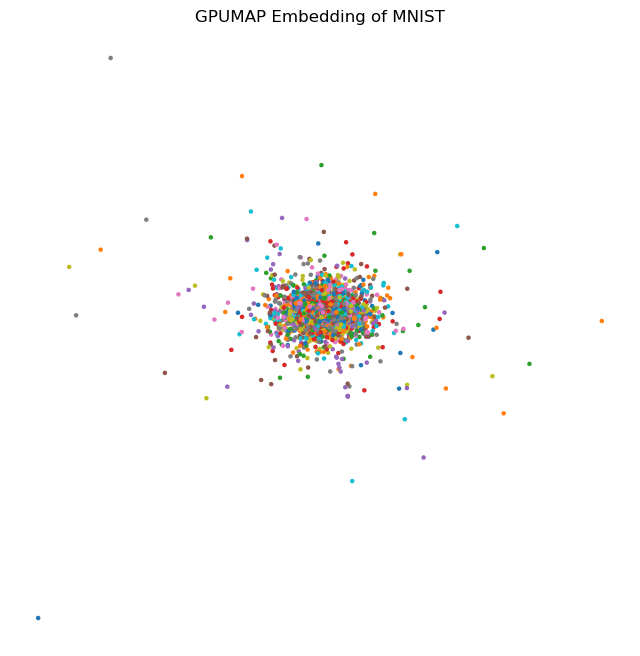

In [8]:
plt.figure(figsize=(8, 8))
plt.scatter(emb[:, 0], emb[:, 1], c=data_loader.y, cmap="tab10", s=5)
plt.title("GPUMAP Embedding of MNIST")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
from sklearn.neighbors import NearestNeighbors


def compute_knn(X: np.ndarray, k: int):
    """
    X: (N, d) numpy array
    k: number of neighbors

    return
    -------
    indices: (N, k)
    distances: (N, k)
    """

    # kNN 모델 생성
    knn = NearestNeighbors(
        n_neighbors=k,
        algorithm="auto",  # auto / brute / kd_tree / ball_tree
        metric="euclidean",
    )

    # 데이터 fit
    knn.fit(X)

    # 자기 자신 포함 kNN 결과 반환
    distances, indices = knn.kneighbors(X)

    return indices, distances

In [ ]:
X = data_loader.X

indices, distances = compute_knn(X, 16)

In [ ]:
distances_squared = np.square(
    distances[:, 1:]
)  # 자기 자신과의 거리는 제외 (첫 번째 열)
print(distances_squared)

In [ ]:
print(gpumap.get_neighbor_dists().get())

In [ ]:
for i in range(10):
    gpumap.run_with_n_ops(0, 10000, 0)

In [ ]:
print(gpumap.get_neighbor_dists().get())

In [ ]:
# exact kNN(indices) vs GPUMAP neighbor indices recall@k 계산

# GPUMAP 결과(approx) 인덱스
approx_indices = ni.get() if hasattr(ni, "get") else ni  # shape: (N, k)

# exact kNN 인덱스 (첫 컬럼은 자기 자신이므로 제외)
k = approx_indices.shape[1]
exact_indices = indices[:, 1 : 1 + k]  # shape: (N, k)

# 샘플별 recall@k
match_counts = np.array(
    [
        len(set(exact_indices[i]).intersection(set(approx_indices[i])))
        for i in range(exact_indices.shape[0])
    ],
    dtype=np.float32,
)
recall_per_sample = match_counts / k
mean_recall = recall_per_sample.mean()

print(f"Recall@{k}: {mean_recall:.6f}")
print(
    f"Min/Max recall@{k}: {recall_per_sample.min():.6f} / {recall_per_sample.max():.6f}"
)

In [ ]:
approx_dists = gpumap.get_neighbor_dists().get()
exact_dists = distances[:, 1 : 1 + k]

diff = np.abs(approx_dists - exact_dists)
print(f"Mean abs distance diff: {diff.mean():.6f}")
print(f"Max abs distance diff: {diff.max():.6f}")
print(f"Min abs distance diff: {diff.min():.6f}")
print(f"Sum abs distance diff: {diff.sum():.6f}")